# How we chose our spam classifier

**Final recipe:** 50% binned logistic regression, 25% KNN-imputed RBF SVM,
and 25% logistic regression with interactions.

This notebook answers three questions: **Which other models did we compare?
Why these three components? Does combining them actually help?** Read the
saved tables and explanations, or Run All to reproduce them.

Keep `spamTrain1.csv` and `classifySpam.py` beside this notebook. In Colab,
upload those two files when prompted. The default uses the original ten seeds
× five folds; set `QUICK_RUN=True` for a five-fold check. No parameter search
runs here. Full search code and original results remain in
[the archive](archive/exploration_full.ipynb).

Tested locally with scikit-learn 1.9.0; the submission requires >=1.2 and <1.11.
Colab itself has not been tested here.

In [1]:
from pathlib import Path
import hashlib
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, PolynomialFeatures
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
from threadpoolctl import threadpool_limits

warnings.filterwarnings('ignore', category=FutureWarning,
                       message='The `probability` parameter was deprecated')
QUICK_RUN = False
seeds = [19] if QUICK_RUN else [19, 43, 101, 521, 991, 2011, 4001, 7001, 12007, 19937]
print(f'scikit-learn {sklearn.__version__}; {5 * len(seeds)} folds per model.')

scikit-learn 1.9.0; 50 folds per model.


## 1. Understand the data

Each email has **30 word-frequency features** and a label: `0` = ham, `1` = spam.
**`-1` means missing; `0` means the word was observed to be absent.** Treating
them as the same value would discard information.

We retain the original split: **1,125 development emails** and **375 previously
examined audit emails**. Every validation run below uses only the development
portion; the audit portion is not a fresh, untouched test set.

In [2]:
required = ('spamTrain1.csv', 'classifySpam.py')
if any(not Path(name).exists() for name in required):
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError('Place spamTrain1.csv and classifySpam.py beside this notebook.') from exc
    print('Upload spamTrain1.csv and classifySpam.py.')
    files.upload()
if any(not Path(name).exists() for name in required):
    raise FileNotFoundError('Both files are required with their original names.')

# Use the submission implementation directly, avoiding a second copy.
from classifySpam import predictTest

raw = np.loadtxt('spamTrain1.csv', delimiter=',')
if raw.ndim != 2 or raw.shape[1] != 31 or not np.isin(raw[:, -1], [0, 1]).all():
    raise ValueError('Expected 30 features and one 0/1 label column, without a header.')
if not np.isfinite(raw).all() or ((raw[:, :-1] < 0) & (raw[:, :-1] != -1)).any():
    raise ValueError('Features must be nonnegative, with -1 for missing values.')
development, audit = train_test_split(
    np.arange(len(raw)), test_size=0.25, stratify=raw[:, -1], random_state=3402026)
X, y = raw[development, :-1], raw[development, -1].astype(int)

display(pd.Series({
    'Development emails': len(X),
    'Excluded audit emails': len(audit),
    'Spam in development (%)': round(100 * y.mean(), 1),
    'Missing entries in development (%)': round(100 * (X == -1).mean(), 1),
    'Zeros among observed entries (%)': round(100 * (X == 0).sum() / (X >= 0).sum(), 1),
}, name='Data overview').to_frame())

,Data overview
Development emails,1125.0
Excluded audit emails,375.0
Spam in development (%),41.4
Missing entries in development (%),20.1
Zeros among observed entries (%),81.9


## 2. A fair, compact comparison

We compare **11 alternatives and the 3 selected components**. Their fixed
settings come from the archived search. They are representative configurations,
**not the original best score from every model family**; a weaker row does not
establish that the whole family is unsuitable.

Every model receives the same development folds. All learned preprocessing
happens inside each training fold. We measure **AUC** and the instructor's
**linearly interpolated TPR at 1% FPR**, then average fold scores.

The helper code below expresses the selected components as sklearn pipelines.
The run checks that their weighted output matches the actual `classifySpam.py`
implementation on the first fold. The model definitions show the settings used.

In [3]:
def missing_to_nan(values):
    """Preserve observed zeros; convert only the missing-value marker."""
    return np.where(np.asarray(values) == -1, np.nan, values).astype(float)


def log_frequencies(values):
    return np.log1p(1000 * missing_to_nan(values))


def log_and_presence(values):
    values = missing_to_nan(values)
    presence = np.where(np.isnan(values), np.nan, (values > 0).astype(float))
    return np.hstack((np.log1p(1000 * values), presence))


class ZeroAwareBins(TransformerMixin, BaseEstimator):
    """Encode absent/low/high frequency and presence, using training priors for missing values."""

    def fit(self, values, labels=None):
        self.edges_, self.priors_ = [], []
        for column in missing_to_nan(values).T:
            observed = column[np.isfinite(column)]
            positive = observed[observed > 0]
            if len(positive):
                edges = np.unique(np.expm1(np.linspace(
                    np.log1p(1000 * positive.min()),
                    np.log1p(1000 * positive.max()), 3,
                )[1:-1]) / 1000)
            else:
                edges = np.array([])
            codes = np.where(observed > 0, 1 + np.searchsorted(edges, observed, side='right'), 0)
            counts = np.bincount(codes, minlength=len(edges) + 2).astype(float)
            if not counts.sum():
                counts[0] = 1  # Entirely missing training column: default to absence.
            self.edges_.append(edges)
            self.priors_.append(counts / counts.sum())
        return self

    def transform(self, values):
        columns = []
        for column, edges, prior in zip(missing_to_nan(values).T, self.edges_, self.priors_):
            codes = np.where(column > 0, 1 + np.searchsorted(edges, column, side='right'), 0)
            encoded = np.eye(len(prior))[codes]
            encoded[np.isnan(column)] = prior
            columns.append(np.column_stack((1 - encoded[:, 0], encoded)))
        return np.hstack(columns)


def component_models():
    """Return fresh, unfitted pipelines; each fold learns its own preprocessing."""
    return {
        'Binned logistic regression': make_pipeline(
            ZeroAwareBins(),
            LogisticRegression(C=1, max_iter=3000, random_state=340),
        ),
        'RBF SVM (KNN imputation)': make_pipeline(
            FunctionTransformer(log_frequencies),
            KNNImputer(n_neighbors=31, weights='uniform', keep_empty_features=True),
            StandardScaler(),
            SVC(C=10, gamma=0.003, probability=True, random_state=340, cache_size=256),
        ),
        'Interaction logistic regression': make_pipeline(
            FunctionTransformer(log_and_presence),
            SimpleImputer(strategy='mean', keep_empty_features=True),
            PolynomialFeatures(degree=2, interaction_only=True, include_bias=False),
            StandardScaler(),
            LogisticRegression(C=0.001, max_iter=3000, random_state=340),
        ),
    }

In [4]:
def presence_only(values):
    values = missing_to_nan(values)
    return np.where(np.isnan(values), np.nan, (values > 0).astype(float))

def prepared(estimator, transform=log_and_presence, strategy='mean', scale=True,
             neighbors=None, indicators=False):
    imputer = (KNNImputer(n_neighbors=neighbors, weights='uniform', keep_empty_features=True)
               if neighbors else SimpleImputer(strategy=strategy, add_indicator=indicators,
                                               keep_empty_features=True))
    steps = [FunctionTransformer(transform), imputer]
    if scale:
        steps.append(StandardScaler())
    return make_pipeline(*steps, estimator)

def candidate_models():
    return {
        'Gaussian NB baseline': prepared(GaussianNB(), missing_to_nan, scale=False),
        'Bernoulli NB': prepared(BernoulliNB(alpha=1), presence_only, strategy='median', scale=False),
        'Log/presence logistic': prepared(LogisticRegression(C=.03, max_iter=3000, random_state=340)),
        'KNN-imputed logistic': prepared(LogisticRegression(C=.03, max_iter=3000, random_state=340), neighbors=31),
        'Linear SVM': prepared(LinearSVC(C=.01, dual=False, max_iter=10000, random_state=340)),
        'KNN classifier': prepared(KNeighborsClassifier(n_neighbors=31, weights='distance', p=2), log_frequencies),
        'Decision tree': prepared(DecisionTreeClassifier(min_samples_leaf=15, random_state=340),
                                 missing_to_nan, strategy='median', scale=False, indicators=True),
        'Random forest': prepared(RandomForestClassifier(n_estimators=300, max_features=.3,
                                 min_samples_leaf=10, n_jobs=2, random_state=340), missing_to_nan, scale=False),
        'Extra trees': prepared(ExtraTreesClassifier(n_estimators=300, max_features=.3,
                               min_samples_leaf=5, n_jobs=2, random_state=340), missing_to_nan, scale=False),
        'Histogram boosting': make_pipeline(FunctionTransformer(missing_to_nan),
            HistGradientBoostingClassifier(max_iter=400, learning_rate=.05, max_leaf_nodes=3,
                min_samples_leaf=10, l2_regularization=.1, early_stopping=False, random_state=340)),
        'Small neural network': prepared(MLPClassifier(hidden_layer_sizes=(16,), alpha=100,
            solver='lbfgs', max_iter=3000, max_fun=50000, random_state=340)),
        **component_models(),
    }

## 3. Run the models and combination checks

The three component scores are reused to test singles, pairs, equal weights,
and the final weights. Removing a component **renormalizes the remaining
original weights**. These checks require no additional model search.

`KNN classifier` uses neighbors to score spam; `KNN-imputed logistic` and the
selected RBF SVM instead use neighbors to fill missing features. They answer
different modeling questions. Linear SVM returns ranking scores; only the three
selected models' probability outputs are combined.

In [5]:
component_names = list(component_models())
blend_weights = {
    'Binned LR alone': (1, 0, 0),
    'RBF SVM alone': (0, 1, 0),
    'Interaction LR alone': (0, 0, 1),
    'Without binned LR': (0, .5, .5),
    'Without RBF SVM': (2/3, 0, 1/3),
    'Without interactions': (2/3, 1/3, 0),
    'Equal-weight trio': (1/3, 1/3, 1/3),
    'Final 50/25/25': (.5, .25, .25),
}

def score_metrics(labels, scores):
    fpr, tpr, _ = roc_curve(labels, scores)
    i = np.flatnonzero(fpr <= .01)[-1]
    tpr_at = tpr[i] + (tpr[i+1] - tpr[i]) * (.01 - fpr[i]) / (fpr[i+1] - fpr[i])
    return {'AUC': roc_auc_score(labels, scores), 'TPR (%)': 100 * tpr_at}

model_rows, blend_rows, warning_rows = [], [], []
started = time.perf_counter()
with threadpool_limits(limits=2):
    for seed in seeds:
        for fold, (train, validation) in enumerate(StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y)):
            predictions = {}
            for name, model in candidate_models().items():
                with warnings.catch_warnings(record=True) as notices:
                    model.fit(X[train], y[train])
                    scores = (model.predict_proba(X[validation])[:, 1] if hasattr(model, 'predict_proba')
                              else model.decision_function(X[validation]))
                warning_rows.extend({'Model': name, 'Warning': str(w.message)} for w in notices)
                predictions[name] = scores
                model_rows.append({'Model': name, 'Seed': seed, 'Fold': fold,
                                   **score_metrics(y[validation], scores)})
            parts = np.array([predictions[name] for name in component_names])
            for name, weights in blend_weights.items():
                scores = np.array(weights) @ parts
                blend_rows.append({'Model': name, 'Seed': seed, 'Fold': fold,
                                   **score_metrics(y[validation], scores)})
                if name == 'Final 50/25/25' and seed == seeds[0] and fold == 0:
                    np.testing.assert_allclose(scores, predictTest(X[train], y[train], X[validation]),
                                               rtol=1e-9, atol=1e-10)
        print(f'Completed seed {seed}: {time.perf_counter() - started:.1f}s elapsed.')
model_results, blend_results = pd.DataFrame(model_rows), pd.DataFrame(blend_rows)
if warning_rows:
    display(pd.DataFrame(warning_rows).value_counts().rename('Occurrences').reset_index())
print('Submission parity check passed. Each row below summarizes', 5 * len(seeds), 'folds.')

Completed seed 19: 5.3s elapsed.
Completed seed 43: 10.5s elapsed.
Completed seed 101: 15.4s elapsed.
Completed seed 521: 20.2s elapsed.
Completed seed 991: 25.1s elapsed.
Completed seed 2011: 30.9s elapsed.
Completed seed 4001: 36.0s elapsed.
Completed seed 7001: 41.8s elapsed.
Completed seed 12007: 47.0s elapsed.
Completed seed 19937: 52.9s elapsed.
Submission parity check passed. Each row below summarizes 50 folds.


  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 420, in _count_physical_cores_darwin
    return int(cpu_info)
           ^^^^^^^^^^^^^


,Model,Warning,Occurrences
0,KNN classifier,Could not find the number of physical cores fo...,1


## 4. How do the other models compare?

**Higher is better for both metrics.** Compare each alternative with the final
ensemble, and notice whether an AUC improvement costs low-FPR detection.
Standard deviations describe fold variation, not confidence intervals.

In [6]:
def summarize(frame):
    return frame.groupby('Model', sort=False).agg(
        AUC=('AUC', 'mean'), AUC_SD=('AUC', 'std'),
        TPR_percent=('TPR (%)', 'mean'), TPR_SD_pp=('TPR (%)', 'std'))

final_rows = blend_results[blend_results.Model == 'Final 50/25/25']
comparison = summarize(pd.concat([model_results, final_rows])).sort_values('AUC', ascending=False)
display(comparison.round({'AUC': 5, 'AUC_SD': 5, 'TPR_percent': 2, 'TPR_SD_pp': 2}))

final_mean = comparison.loc['Final 50/25/25']
challengers = comparison.drop(index=component_names + ['Final 50/25/25'])
stronger_both = challengers[(challengers.AUC > final_mean.AUC) &
                           (challengers.TPR_percent > final_mean.TPR_percent)]
if len(stronger_both):
    print('Alternatives ahead on both means in this run:', ', '.join(stronger_both.index))
else:
    print('No representative alternative beats the final ensemble on both means in this run.')
print('Best alternative AUC:', challengers.AUC.idxmax(), '| best alternative TPR:', challengers.TPR_percent.idxmax())

No representative alternative beats the final ensemble on both means in this run.
Best alternative AUC: KNN-imputed logistic | best alternative TPR: Log/presence logistic


,AUC,AUC_SD,TPR_percent,TPR_SD_pp
Model,,,,
Final 50/25/25,0.92395,0.01434,57.86,9.78
KNN-imputed logistic,0.92194,0.01485,53.93,11.04
Log/presence logistic,0.92019,0.01495,53.99,10.90
Linear SVM,0.91942,0.01486,53.50,11.95
Small neural network,0.91906,0.01529,52.92,10.68
Binned logistic regression,0.91891,0.01548,52.79,11.98
RBF SVM (KNN imputation),0.91819,0.01604,49.36,14.21
Interaction logistic regression,0.91679,0.01353,51.01,11.56
Histogram boosting,0.91597,0.01340,49.23,14.69


## 5. Why these three models together?

The selected models need not be the top three individual classifiers. The
relevant question is whether their **combination** improves both target metrics.

| Component | What it contributes | Important settings |
| --- | --- | --- |
| Binned logistic, 50% | Coarse absent/low/high frequency effects plus presence; missing values use training category proportions | `C=1`; boundary at midpoint of positive training min/max on log scale |
| RBF SVM, 25% | Nonlinear similarities between emails after filling missing log frequencies from neighbors | 31 neighbors; scaling after imputation; `C=10`, `gamma=.003` |
| Interaction logistic, 25% | Pairwise word-frequency/presence effects that an additive model misses | Mean imputation; 1,830 features; scaling; strong regularization `C=.001` |

Log features use `log1p(1000 × frequency)`. **The table below tests the proposed
complementarity.** A pair that matches or beats the trio weakens the case for
the omitted component on that metric; a more complex blend is not automatically better.

In [7]:
ablations = summarize(blend_results).reindex(blend_weights)
ablations['AUC_gain_vs_variant'] = ablations.loc['Final 50/25/25', 'AUC'] - ablations.AUC
ablations['TPR_gain_vs_variant_pp'] = ablations.loc['Final 50/25/25', 'TPR_percent'] - ablations.TPR_percent
display(ablations[['AUC', 'TPR_percent', 'AUC_gain_vs_variant', 'TPR_gain_vs_variant_pp']].round(5))
print('Gain columns = final trio minus the row. Positive favors the final trio; negative favors the row.')

paired = []
final_folds = final_rows.set_index(['Seed', 'Fold'])
for name in ['Without binned LR', 'Without RBF SVM', 'Without interactions']:
    variant = blend_results[blend_results.Model == name].set_index(['Seed', 'Fold'])
    delta = final_folds['TPR (%)'] - variant['TPR (%)']
    paired.append({'Variant': name, 'Trio TPR wins': int((delta > 1e-10).sum()),
                   'Ties': int((delta.abs() <= 1e-10).sum()), 'Trio TPR losses': int((delta < -1e-10).sum())})
display(pd.DataFrame(paired).set_index('Variant'))

Gain columns = final trio minus the row. Positive favors the final trio; negative favors the row.


,AUC,TPR_percent,AUC_gain_vs_variant,TPR_gain_vs_variant_pp
Model,,,,
Binned LR alone,0.91891,52.79204,0.00504,5.06955
RBF SVM alone,0.91819,49.35667,0.00576,8.50492
Interaction LR alone,0.91679,51.00641,0.00716,6.85518
Without binned LR,0.92234,55.71723,0.00161,2.14436
Without RBF SVM,0.92205,55.86205,0.00190,1.99954
Without interactions,0.92291,55.91146,0.00104,1.95013
Equal-weight trio,0.92439,57.62755,-0.00044,0.23404
Final 50/25/25,0.92395,57.86159,0.00000,0.00000


,Trio TPR wins,Ties,Trio TPR losses
Variant,,,
Without binned LR,28,2,20
Without RBF SVM,29,5,16
Without interactions,34,3,13


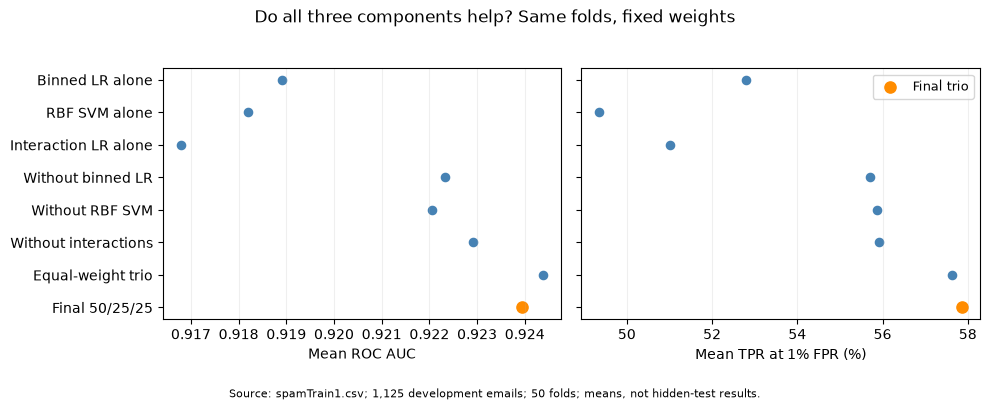

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
positions = np.arange(len(ablations))
for ax, metric, label in zip(axes, ['AUC', 'TPR_percent'], ['Mean ROC AUC', 'Mean TPR at 1% FPR (%)']):
    ax.scatter(ablations[metric], positions, color='steelblue', s=35)
    ax.scatter(ablations.loc['Final 50/25/25', metric], len(ablations)-1, color='darkorange', s=65, label='Final trio')
    ax.set(xlabel=label, yticks=positions, yticklabels=ablations.index)
    ax.grid(axis='x', alpha=.2)
axes[0].invert_yaxis()
axes[1].legend(loc='best', fontsize=9)
fig.suptitle('Do all three components help? Same folds, fixed weights')
fig.text(.5, .01, f'Source: spamTrain1.csv; 1,125 development emails; {5 * len(seeds)} folds; means, not hidden-test results.',
         ha='center', fontsize=8)
fig.tight_layout(rect=(0, .06, 1, .95))
plt.show()

**Reading the saved 50-fold results above:** the trio beats every individual
model tested on both means, even though some alternatives beat its components
individually. This supports combining complementary models, rather than simply
choosing the three highest-ranked standalone models.

Removing binned LR, the SVM, or interactions lowers TPR by **2.14, 2.00, or 1.95
percentage points**, respectively, and also lowers AUC. These are useful paired
development comparisons, not proof of statistical significance.

**The weights involve a trade-off:** equal thirds give slightly higher AUC
(**0.92439 vs 0.92395**), while 50/25/25 gives slightly higher TPR
(**57.86% vs 57.63%**). These results support the trio more clearly than they
establish an optimal weighting. A five-fold quick run may tell a different story.

## 6. What the earlier search taught us

The archived run explored **1,841 configurations**, re-evaluated 165 finalists,
and compared **29,000 ensemble weight/method combinations**. It also covered
Perceptron/Adaline, LDA/PCA, feature selection, gradient boosting/AdaBoost,
splines, alternative kernels, binning, and imputation. XGBoost, LightGBM, and
CatBoost were unavailable and were not tested.

- **KNN-imputed logistic:** its initial screening advantage in low-FPR detection did not persist in broader comparisons.
- **An all-logistic blend:** lost its advantage in the 50-holdout check.
- **High-AUC blends:** some sacrificed low-FPR detection, so AUC alone did not decide the model.
- **Automated nested selection:** underperformed the previous classifier. The search procedure itself was unstable.

These are historical findings from the archive, not conclusions manufactured
from today's representative table. The stored previous-vs-final comparison below
uses the original ten seeds × five folds and was independently reproduced during review.

In [9]:
recorded_csv_hash = '1cc074784a0c6dc05b2e784ae9f38e1a76886f168f904720d93a755342e15df5'
recorded_model_hash = 'aebaee448affafc3dd6dd9ef9de50f447c86a3f8c69dd610e241ce52233b1a9b'
matches_record = (
    hashlib.sha256(Path('spamTrain1.csv').read_bytes()).hexdigest() == recorded_csv_hash
    and hashlib.sha256(Path('classifySpam.py').read_bytes()).hexdigest() == recorded_model_hash
)
if matches_record:
    historical = pd.DataFrame([
        ['Previous ensemble', 0.9221003556710096, 55.22077327842598],
        ['Final ensemble', 0.9239492662218174, 57.86158773735986],
    ], columns=['Model', 'Mean AUC', 'Mean TPR at 1% FPR (%)']).set_index('Model')
    display(historical.round(5))
else:
    print('Data or classifier changed: the historical headline scores describe the archived version only.')

,Mean AUC,Mean TPR at 1% FPR (%)
Model,,
Previous ensemble,0.92210,55.22077
Final ensemble,0.92395,57.86159


The historical gain over the previous ensemble was **+0.00185 AUC** and
**+2.64 percentage points TPR**. Simple 50/25/25 weights were retained after
several development checks; they are not proven universally optimal.

## 7. Limits and next steps

- **Only about 132 ham emails per validation fold:** at 1% FPR, one or two unusual ham rankings can change TPR sharply.
- **Selection bias:** all these comparisons reuse development emails consulted during model selection. More split seeds do not create independent observations.
- **No guaranteed winner:** small mean differences and overlapping folds do not prove statistical significance or leaderboard rank.
- **Nested diagnostic:** evaluates automated selection, not the final fixed blend; the library itself had already been developed on these emails.

AUC is a ranking metric, not classification accuracy. TPR of 57.86% at 1% FPR
means detecting about 58% of spam while flagging 1% of ham under that protocol.

**Next:** pre-submit `classifySpam.py`, evaluate the frozen recipe on the newly
released labeled data before tuning, and use these comparisons and limitations
in the report. Discuss false-positive costs, user corrections, and retraining.
The instructor's evaluator needs a separate labeled test CSV; evaluating on
the training CSV would not measure generalization.

For every original grid and robustness experiment, open
[the full archive](archive/exploration_full.ipynb) with this project as the
kernel working directory (or upload its CSV in Colab).